In [1]:
import numpy as np
import matplotlib.pylab as plt
import xarray as xr
import os
import pickle  ## unnecessary for final version

#import sys
import xgcm  ## unnecessary for final version
from xmitgcm import open_mdsdataset  ## unnecessary for final version
import MITgcmutils  ## unnecessary for final version
import matplotlib.ticker as mticker  ## unnecessary for final version

In [2]:
dir = '/scratch/users/nbcoffey/sose_data'

In [3]:
# Test each file one at a time
print("Testing grid.nc...")
try:
    grid = xr.open_dataset(os.path.join(dir, 'grid.nc'))
    print("✓ grid.nc loaded successfully")
    print(grid)
except Exception as e:
    print(f"✗ grid.nc failed: {e}")

print("\nTesting oceTAUX...")
try:
    taux = xr.open_dataset(os.path.join(dir, 'oceTAUX_bsoseI156_2013to2024_monthly.nc'))
    print("✓ oceTAUX loaded successfully")
    print(taux)
except Exception as e:
    print(f"✗ oceTAUX failed: {e}")

print("\nTesting oceTAUY...")  ## unnecessary for final version
try:  ## unnecessary for final version
    tauy = xr.open_dataset(os.path.join(dir, 'oceTAUY_bsoseI156_2013to2024_monthly.nc'))  ## unnecessary for final version
    print("✓ oceTAUY loaded successfully")  ## unnecessary for final version
    print(tauy)  ## unnecessary for final version
except Exception as e:  ## unnecessary for final version
    print(f"✗ oceTAUY failed: {e}")  ## unnecessary for final version

print("\nTesting Theta...")
try:
    theta = xr.open_dataset(os.path.join(dir, 'Theta_bsoseI156_2013to2024_monthly.nc'))
    print("✓ Theta loaded successfully")
    print(theta)
except Exception as e:
    print(f"✗ Theta failed: {e}")

print("\nTesting Uvel...")
try:
    uvel = xr.open_dataset(os.path.join(dir, 'Uvel_bsoseI156_2013to2024_monthly.nc'))
    print("✓ Uvel loaded successfully")
    print(uvel)
except Exception as e:
    print(f"✗ Uvel failed: {e}")

print("\nTesting Vvel...")
try:
    vvel = xr.open_dataset(os.path.join(dir, 'Vvel_bsoseI156_2013to2024_monthly.nc'))
    print("✓ Vvel loaded successfully")
    print(vvel)
except Exception as e:
    print(f"✗ Vvel failed: {e}")

Testing grid.nc...
✓ grid.nc loaded successfully
<xarray.Dataset>
Dimensions:  (NX: 2160, NY: 588, NZ: 52, NZ+1: 53)
Dimensions without coordinates: NX, NY, NZ, NZ+1
Data variables:
    hFacC    (NZ, NY, NX) float64 ...
    hFacS    (NZ, NY, NX) float64 ...
    hFacW    (NZ, NY, NX) float64 ...
    RC       (NZ) float64 ...
    RF       (NZ+1) float64 ...
    DRC      (NZ+1) float64 ...
    DRF      (NZ) float64 ...
    RAC      (NY, NX) float64 ...
    RAS      (NY, NX) float64 ...
    RAW      (NY, NX) float64 ...
    XC       (NY, NX) float64 ...
    XG       (NY, NX) float64 ...
    YC       (NY, NX) float64 ...
    YG       (NY, NX) float64 ...
    DXC      (NY, NX) float64 ...
    DXG      (NY, NX) float64 ...
    DYC      (NY, NX) float64 ...
    DYG      (NY, NX) float64 ...
    Depth    (NY, NX) float64 ...

Testing oceTAUX...
✓ oceTAUX loaded successfully
<xarray.Dataset>
Dimensions:  (XG: 2160, YC: 588, time: 144)
Coordinates:
    iter     (time) int64 ...
  * time     (time

In [4]:
import numpy as np
import xarray as xr

# Compute ross_taux_yearly (zonal average and yearly average)
ross_taux = taux['oceTAUX'].sel(
    XG=slice(160, 280),  # Same longitude range as temperature plots
#     YC=slice(-75, -50)   # Same latitude range
    YC=slice(-90, -50)   # Same latitude range
)

# Compute zonal average over Ross Gyre sector
ross_taux_zonal = ross_taux.mean(dim='XG')

# Compute yearly averages
ross_taux_yearly = ross_taux_zonal.groupby('time.year').mean(dim='time')

print("ross_taux_yearly computed successfully!")
print(f"Shape: {ross_taux_yearly.shape}")
print(f"Years available: {ross_taux_yearly.year.values}")

ross_taux_yearly computed successfully!
Shape: (12, 427)
Years available: [2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]


In [5]:
# Find y extent

# ============================================================================
# DETERMINE ACTUAL Y-EXTENT
# ============================================================================
print("\n" + "="*70)
print("Y-AXIS EXTENT ANALYSIS")
print("="*70)

# Get the YC coordinate values
yc_values = ross_taux_yearly.YC.values

print(f"\nRequested YC slice: -90 to -50")
print(f"Actual YC min: {yc_values.min():.4f}°S")
print(f"Actual YC max: {yc_values.max():.4f}°S")
print(f"Number of YC points: {len(yc_values)}")
print(f"\nFirst 5 YC values: {yc_values[:5]}")
print(f"Last 5 YC values: {yc_values[-5:]}")

# Check for any NaN values in the data at the extremes
print("\n" + "-"*70)
print("DATA AVAILABILITY CHECK")
print("-"*70)

# Check southern extent (most negative latitudes)
south_data = ross_taux_yearly.isel(YC=slice(0, 10))
print(f"\nSouthernmost 10 points:")
for i in range(min(10, len(yc_values))):
    yc = yc_values[i]
    n_valid = np.sum(~np.isnan(ross_taux_yearly.isel(YC=i).values))
    n_total = ross_taux_yearly.isel(YC=i).size
    print(f"  YC = {yc:7.3f}°S: {n_valid}/{n_total} valid values")

# Check northern extent (least negative latitudes)
print(f"\nNorthernmost 10 points:")
for i in range(max(0, len(yc_values)-10), len(yc_values)):
    yc = yc_values[i]
    n_valid = np.sum(~np.isnan(ross_taux_yearly.isel(YC=i).values))
    n_total = ross_taux_yearly.isel(YC=i).size
    print(f"  YC = {yc:7.3f}°S: {n_valid}/{n_total} valid values")

# Find the actual data range (excluding NaNs)
print("\n" + "-"*70)
print("ACTUAL DATA RANGE (NON-NAN VALUES)")
print("-"*70)

# For each year, find where data exists
for year in ross_taux_yearly.year.values[:3]:  # Just check first 3 years as example
    year_data = ross_taux_yearly.sel(year=year)
    valid_mask = ~np.isnan(year_data.values)
    
    if np.any(valid_mask):
        valid_yc = yc_values[valid_mask]
        print(f"\nYear {year}:")
        print(f"  Data range: {valid_yc.min():.3f}°S to {valid_yc.max():.3f}°S")
        print(f"  Valid points: {np.sum(valid_mask)}/{len(yc_values)}")

# Overall valid range across all years
all_valid_mask = ~np.isnan(ross_taux_yearly.values).all(axis=0)
if np.any(all_valid_mask):
    valid_yc_all = yc_values[all_valid_mask]
    print(f"\nOverall (all years):")
    print(f"  Data range: {valid_yc_all.min():.3f}°S to {valid_yc_all.max():.3f}°S")
    print(f"  Valid latitude points: {np.sum(all_valid_mask)}/{len(yc_values)}")
    
    print("\n" + "="*70)
    print("RECOMMENDED Y-LIMITS FOR PLOTTING:")
    print("="*70)
    print(f"ax.set_ylim({valid_yc_all.min():.2f}, {valid_yc_all.max():.2f})")
else:
    print("\nWARNING: No valid data found!")


Y-AXIS EXTENT ANALYSIS

Requested YC slice: -90 to -50
Actual YC min: -77.9827°S
Actual YC max: -50.0545°S
Number of YC points: 427

First 5 YC values: [-77.98265  -77.9479   -77.91305  -77.8781   -77.843056]
Last 5 YC values: [-50.480625 -50.37445  -50.26804  -50.161392 -50.0545  ]

----------------------------------------------------------------------
DATA AVAILABILITY CHECK
----------------------------------------------------------------------

Southernmost 10 points:
  YC = -77.983°S: 12/12 valid values
  YC = -77.948°S: 12/12 valid values
  YC = -77.913°S: 12/12 valid values
  YC = -77.878°S: 12/12 valid values
  YC = -77.843°S: 12/12 valid values
  YC = -77.808°S: 12/12 valid values
  YC = -77.773°S: 12/12 valid values
  YC = -77.737°S: 12/12 valid values
  YC = -77.702°S: 12/12 valid values
  YC = -77.666°S: 12/12 valid values

Northernmost 10 points:
  YC = -51.008°S: 12/12 valid values
  YC = -50.903°S: 12/12 valid values
  YC = -50.798°S: 12/12 valid values
  YC = -50.692°S:

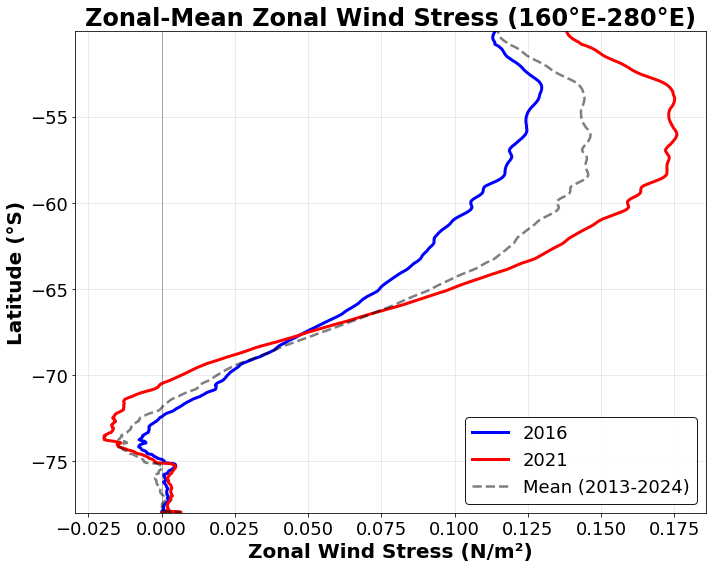


Maxima Details:
2016: Max = 0.129710 N/m² at -53.36°S
2021: Max = 0.175859 N/m² at -56.05°S


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================================
# PUBLICATION SETTINGS
# ============================================================================
BASE_FONTSIZE = 20
TITLE_SIZE = BASE_FONTSIZE + 4
LABEL_SIZE = BASE_FONTSIZE
TICK_SIZE = BASE_FONTSIZE - 2
LEGEND_SIZE = BASE_FONTSIZE - 2

# Select specific years
selected_years = [2016, 2021]
colors_dict = {2016: 'blue', 2019: 'green', 2020: 'orange', 2021: 'red'}

fig, ax = plt.subplots(figsize=(10, 8))
# wind_width = 6  # Adjust this to your preference (smaller = narrower)
# fig, ax = plt.subplots(figsize=(wind_width, 8))

analysis_region = ross_taux_yearly.sel(YC=slice(-90, -50))

for year in selected_years:
    tau_year = analysis_region.sel(year=year)
    color = colors_dict[year]
    
    # Plot the profile
    ax.plot(tau_year.values, tau_year.YC.values, 
            color=color, linewidth=3, label=str(year))

# Add mean profile for reference
mean_profile = analysis_region.mean(dim='year')

# Get the year range from the data
year_min = int(ross_taux_yearly.year.min().values)
year_max = int(ross_taux_yearly.year.max().values)

ax.plot(mean_profile.values, mean_profile.YC.values, 'k--', 
        linewidth=2.5, label=f'Mean ({year_min}-{year_max})', alpha=0.5)

ax.axvline(0, color='k', linestyle='-', linewidth=1, alpha=0.3)
ax.set_xlabel('Zonal Wind Stress (N/m²)', fontsize=LABEL_SIZE, fontweight='bold')
ax.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax.set_title('Zonal-Mean Zonal Wind Stress (160°E-280°E)', 
             fontsize=TITLE_SIZE, fontweight='bold')
ax.margins(y=0)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=LEGEND_SIZE, loc='best', framealpha=0.9, edgecolor='black')
ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()
fig.savefig('zonal_wind_stress_profiles_160e-280e.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig('zonal_wind_stress_profiles_160e-280e.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Print the maxima details
print("\nMaxima Details:")
print("="*60)
for year in selected_years:
    tau_year = analysis_region.sel(year=year)
    max_val = tau_year.max().values
    lat_max = tau_year.YC.values[tau_year.argmax().values]
    print(f"{year}: Max = {max_val:.6f} N/m² at {lat_max:.2f}°S")

Using fixed depth: -450.0 m
Loading 2016...
  2016: -1.74 to 8.65 °C
Loading 2021...
  2021: -1.65 to 9.00 °C
Computing difference...
Loading bathymetry...
Plotting 2016...


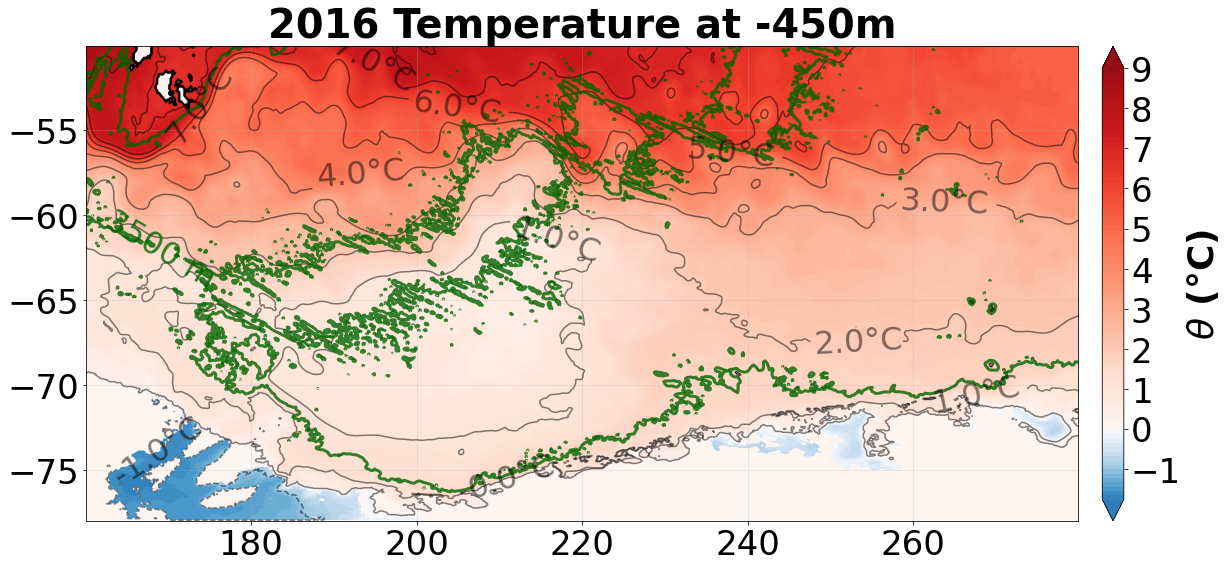

Plotting 2020...


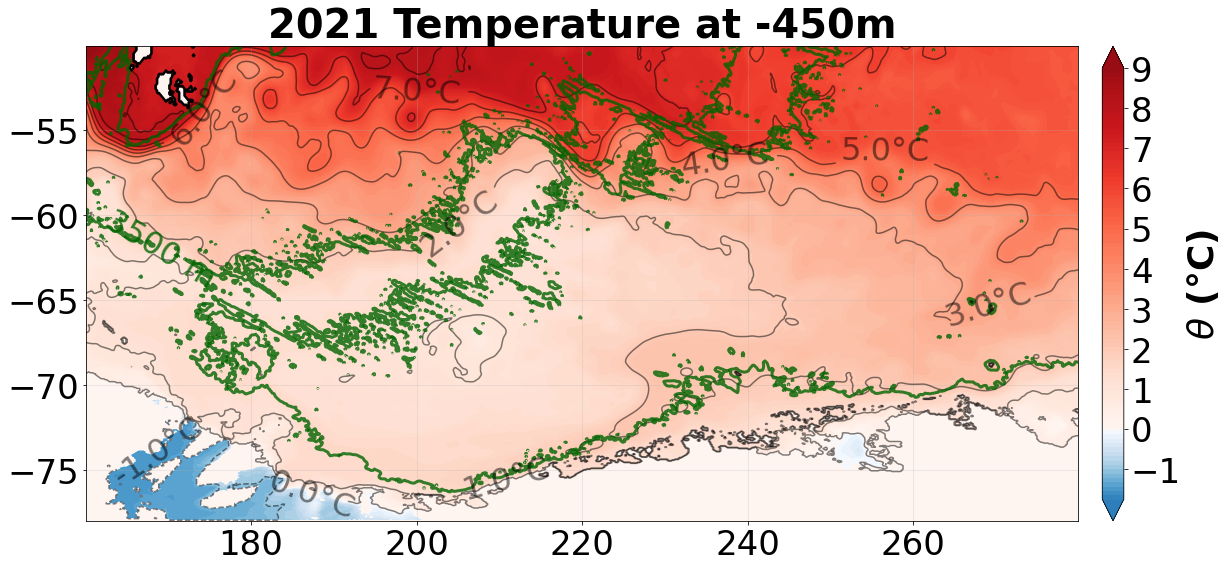

Plotting difference...


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:184: MatplotlibDeprecationWarning: The 'extend' parameter to Colorbar has no effect because it is overridden by the mappable; it is deprecated since 3.3 and will be removed two minor releases later.


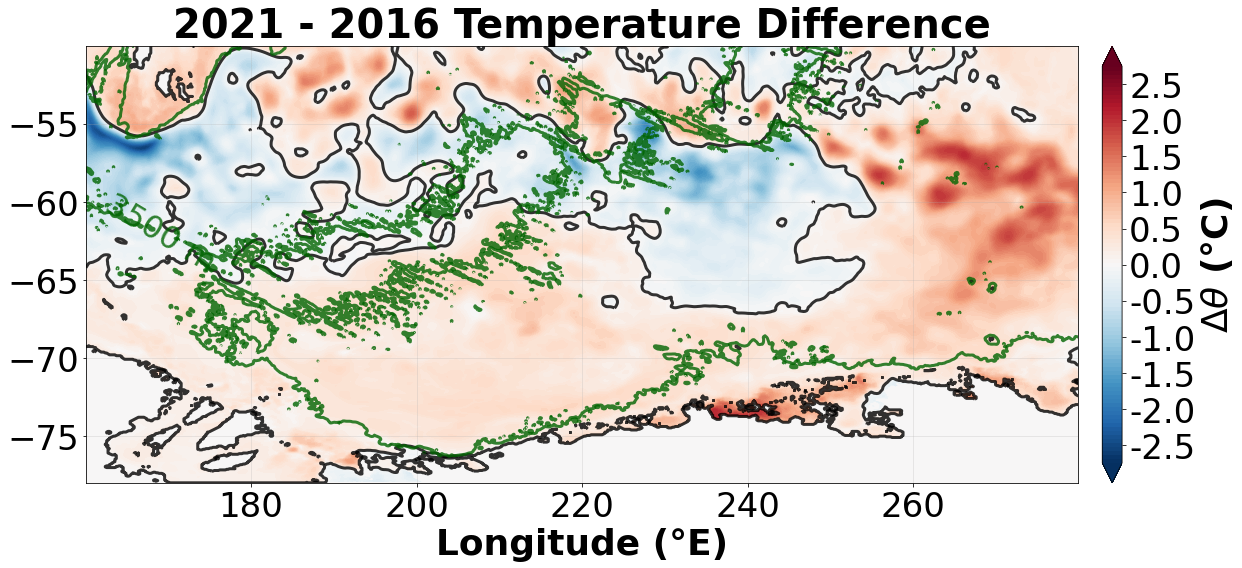


2021 - 2016 COMPARISON
Mean difference: +0.1822 °C
Max warming: +2.0856 °C
Max cooling: -2.6054 °C
Area with warming: 60.4%
Area with cooling: 20.0%


In [17]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# ============================================================================
# PUBLICATION SETTINGS
# ============================================================================
BASE_FONTSIZE = 36 #20  # Adjust this one parameter to scale all fonts
TITLE_SIZE = BASE_FONTSIZE + 4
LABEL_SIZE = BASE_FONTSIZE
TICK_SIZE = BASE_FONTSIZE - 2
CBAR_LABEL_SIZE = BASE_FONTSIZE
CBAR_TICK_SIZE = BASE_FONTSIZE - 2
CONTOUR_LABEL_SIZE = BASE_FONTSIZE - 4

# Just two years
year1 = 2016
year2 = 2021

# Use a fixed depth
target_depth = -450  # meters
depth_idx = np.abs(theta.Z.values - target_depth).argmin()
actual_depth = theta.Z.values[depth_idx]

print(f"Using fixed depth: {actual_depth:.1f} m")

# Load temperature for 2016
print(f"Loading {year1}...")
temp_2016 = theta['THETA'].sel(
    XC=slice(160, 280),
    YC=slice(-90, -50),
    time=str(year1)
).isel(Z=depth_idx).mean(dim='time')

print(f"  {year1}: {temp_2016.min().values:.2f} to {temp_2016.max().values:.2f} °C")

# Load temperature for 2020
print(f"Loading {year2}...")
temp_2020 = theta['THETA'].sel(
    XC=slice(160, 280),
    YC=slice(-90, -50),
    time=str(year2)
).isel(Z=depth_idx).mean(dim='time')

print(f"  {year2}: {temp_2020.min().values:.2f} to {temp_2020.max().values:.2f} °C")

# Compute difference
print("Computing difference...")
temp_diff = temp_2020 - temp_2016

# Get bathymetry for the region
print("Loading bathymetry...")
lon_grid = grid['XC'].values
lat_grid = grid['YC'].values
bathy_grid = grid['Depth'].values

mask_lon = (lon_grid >= 160) & (lon_grid <= 280)
mask_lat = (lat_grid >= -90) & (lat_grid <= -50)
mask = mask_lon & mask_lat
ny_indices, nx_indices = np.where(mask)
ny_min, ny_max = ny_indices.min(), ny_indices.max()
nx_min, nx_max = nx_indices.min(), nx_indices.max()

lon_bathy = lon_grid[ny_min:ny_max+1, nx_min:nx_max+1]
lat_bathy = lat_grid[ny_min:ny_max+1, nx_min:nx_max+1]
bathy_subset = bathy_grid[ny_min:ny_max+1, nx_min:nx_max+1]

# Get ranges
vmin = min(temp_2016.min().values, temp_2020.min().values)
vmax = max(temp_2016.max().values, temp_2020.max().values)

# Create nice colorbar ticks based on data range
def get_nice_ticks(vmin, vmax, target_steps=[0.25, 0.5, 1.0, 2.0, 5.0]):
    """Generate nice tick intervals based on data range"""
    data_range = vmax - vmin
    for step in target_steps:
        n_ticks = data_range / step
        if 5 <= n_ticks <= 15:  # Aim for 5-15 ticks
            tick_min = np.floor(vmin / step) * step
            tick_max = np.ceil(vmax / step) * step
            return np.arange(tick_min, tick_max + step/2, step)
    # Fallback
    return np.linspace(vmin, vmax, 10)

temp_ticks = get_nice_ticks(vmin, vmax)

# Create custom diverging colormap centered at 0
colors_neg = plt.cm.Blues_r(np.linspace(0.3, 1, 128))
colors_pos = plt.cm.Reds(np.linspace(0, 0.9, 128))
all_colors = np.vstack((colors_neg, colors_pos))
temp_cmap = mcolors.LinearSegmentedColormap.from_list('temp_diverging', all_colors)
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)

# Figure 1: 2016
print("Plotting 2016...")
fig1, ax1 = plt.subplots(figsize=(18, 8))
levels = np.linspace(vmin, vmax, 100)
cf1 = ax1.contourf(temp_2016.XC, temp_2016.YC, temp_2016.values,
                   levels=levels, cmap=temp_cmap, norm=norm, extend='both')
temp_contour_levels = np.arange(np.floor(vmin), np.ceil(vmax) + 1, 1.0)
cs1 = ax1.contour(temp_2016.XC, temp_2016.YC, temp_2016.values,
                  levels=temp_contour_levels, colors='black', linewidths=1.5, alpha=0.5)
ax1.clabel(cs1, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.1f°C')

cs_bathy1 = ax1.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='darkgreen', linewidths=3, alpha=0.8)
ax1.clabel(cs_bathy1, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax1.set_title(f'{year1} Temperature at {actual_depth:.0f}m', fontsize=TITLE_SIZE, fontweight='bold')
# ax1.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax1.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.tick_params(labelsize=TICK_SIZE)
cbar1 = plt.colorbar(cf1, ax=ax1, pad=0.02)
cbar1.set_label(r'$\theta$ (°C)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
cbar1.set_ticks(temp_ticks)
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)
plt.tight_layout()
fig1.savefig(f'v1_temperature_{year1}_{actual_depth:.0f}m.png', dpi=300, bbox_inches='tight', facecolor='white')
fig1.savefig(f'v1_temperature_{year1}_{actual_depth:.0f}m.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 2: 2020
print("Plotting 2020...")
fig2, ax2 = plt.subplots(figsize=(18, 8))
cf2 = ax2.contourf(temp_2020.XC, temp_2020.YC, temp_2020.values,
                   levels=levels, cmap=temp_cmap, norm=norm, extend='both')
cs2 = ax2.contour(temp_2020.XC, temp_2020.YC, temp_2020.values,
                  levels=temp_contour_levels, colors='black', linewidths=1.5, alpha=0.5)
ax2.clabel(cs2, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.1f°C')

cs_bathy2 = ax2.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='darkgreen', linewidths=3, alpha=0.8)
ax2.clabel(cs_bathy2, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax2.set_title(f'{year2} Temperature at {actual_depth:.0f}m', fontsize=TITLE_SIZE, fontweight='bold')
# ax2.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax2.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.tick_params(labelsize=TICK_SIZE)
cbar2 = plt.colorbar(cf2, ax=ax2, pad=0.02)
cbar2.set_label(r'$\theta$ (°C)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
cbar2.set_ticks(temp_ticks)
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)
plt.tight_layout()
fig2.savefig(f'v1_temperature_{year2}_{actual_depth:.0f}m.png', dpi=300, bbox_inches='tight', facecolor='white')
fig2.savefig(f'v1_temperature_{year2}_{actual_depth:.0f}m.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 3: Difference
print("Plotting difference...")
# Determine nice range for difference plot
diff_min = temp_diff.min().values
diff_max = temp_diff.max().values
diff_abs_max = max(abs(diff_min), abs(diff_max))
# Round to nice value
nice_diff_max = np.ceil(diff_abs_max * 4) / 4  # Round to nearest 0.5 #0.25
# diff_ticks = get_nice_ticks(-nice_diff_max, nice_diff_max)
# NEW: Create symmetric ticks up to 2.5 (or max nice bound) with 0.5 steps
max_tick = np.floor(nice_diff_max * 2) / 2  # This turns 2.75 into 2.5
step_size = 0.5 if nice_diff_max <= 3.0 else 1.0
diff_ticks = np.arange(-max_tick, max_tick + 0.01, step_size)

fig3, ax3 = plt.subplots(figsize=(18, 8))
diff_norm = mcolors.TwoSlopeNorm(vmin=-nice_diff_max, vcenter=0, vmax=nice_diff_max)
diff_levels = np.linspace(-nice_diff_max, nice_diff_max, 100)
cf3 = ax3.contourf(temp_diff.XC, temp_diff.YC, temp_diff.values,
                   levels=diff_levels, cmap='RdBu_r', norm=diff_norm, extend='both')
cs3 = ax3.contour(temp_diff.XC, temp_diff.YC, temp_diff.values,
                  levels=[0], colors='black', linewidths=3, alpha=0.8)

cs_bathy3 = ax3.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='darkgreen', linewidths=3, alpha=0.8)
ax3.clabel(cs_bathy3, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

# ax3.set_title(f'{year2} - {year1} Temperature Difference at {actual_depth:.0f}m', 
#               fontsize=TITLE_SIZE, fontweight='bold')
ax3.set_title(f'{year2} - {year1} Temperature Difference', 
              fontsize=TITLE_SIZE, fontweight='bold')
ax3.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax3.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.tick_params(labelsize=TICK_SIZE)
cbar3 = plt.colorbar(cf3, ax=ax3, pad=0.02, extend='both')
cbar3.set_label(r'$\Delta \theta$ (°C)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
# cbar3.set_ticks(diff_ticks)
# formatted_tick_labels = [f"{val:.1f}" for val in diff_ticks]
# cbar3.set_ticklabels(formatted_tick_labels)
# NEW: Apply ticks and format labels WITHOUT the plus sign
cbar3.set_ticks(diff_ticks)
cbar3.set_ticklabels([f"{val:.1f}" for val in diff_ticks])
cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig3.savefig(f'v1_temperature_difference_{year2}-{year1}_{actual_depth:.0f}m.png', dpi=300, bbox_inches='tight', facecolor='white')
fig3.savefig(f'v1_temperature_difference_{year2}-{year1}_{actual_depth:.0f}m.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Print statistics
print("\n" + "="*70)
print(f"{year2} - {year1} COMPARISON")
print("="*70)
print(f"Mean difference: {temp_diff.mean().values:+.4f} °C")
print(f"Max warming: {temp_diff.max().values:+.4f} °C")
print(f"Max cooling: {temp_diff.min().values:+.4f} °C")
print(f"Area with warming: {(temp_diff > 0).sum().values / temp_diff.size * 100:.1f}%")
print(f"Area with cooling: {(temp_diff < 0).sum().values / temp_diff.size * 100:.1f}%")

Region: Lon 160.0-280.0°E, Lat -77.98--50.0°S
Using southern boundary: -77.98°S (for psi=0 reference)

UVEL indices: YC[0:427], XG[960:1681]
VVEL indices: YG[1:428], XC[960:1680]

Loading velocity data...
U-vel subset shape: (72, 52, 427, 721)
V-vel subset shape: (72, 52, 427, 720)

Extracting grid metrics from velocity datasets...
hFacW shape: (52, 427, 721)
hFacS shape: (52, 427, 720)
drF shape: (52,)
dyG shape: (427, 721)

COMPUTING MEAN KINETIC ENERGY
Setting up xgcm Grid for interpolation...
U coords: ['iter', 'time', 'YC', 'XG', 'Z', 'dyG', 'dxC', 'rAw', 'drF', 'hFacW', 'maskW', 'rhoRef', 'maskInW', 'rSurfW', 'rLowW']
V coords: ['iter', 'time', 'XC', 'YG', 'Z', 'dxG', 'dyC', 'rAs', 'drF', 'hFacS', 'maskS', 'rhoRef', 'maskInS', 'rSurfS', 'rLowS']

Processing 2016...
U_2016 shape: (427, 721), coords: ('YC', 'XG')
V_2016 shape: (427, 720), coords: ('YG', 'XC')
U_center shape: (427, 720)
V_center shape: (426, 720)
XC coords length: 720
YC coords length: 427
U_center X dimension match

/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:335: MatplotlibDeprecationWarning: The 'extend' parameter to Colorbar has no effect because it is overridden by the mappable; it is deprecated since 3.3 and will be removed two minor releases later.


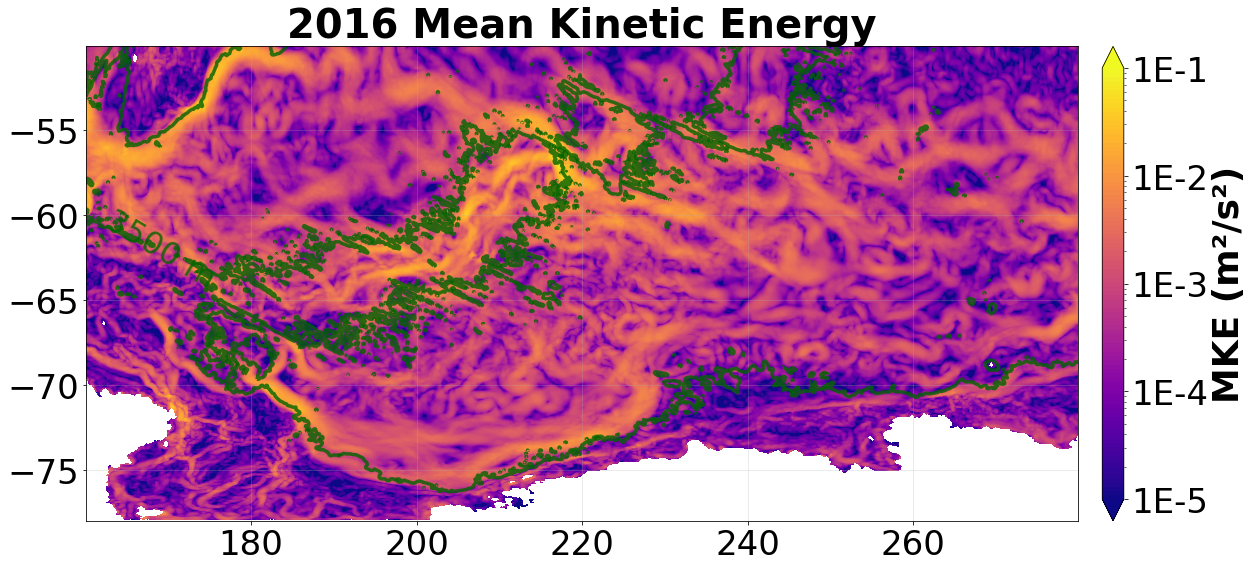

Plotting 2021...


/share/software/user/open/py-jupyterlab/2.3.2_py36/lib/python3.6/site-packages/ipykernel_launcher.py:368: MatplotlibDeprecationWarning: The 'extend' parameter to Colorbar has no effect because it is overridden by the mappable; it is deprecated since 3.3 and will be removed two minor releases later.


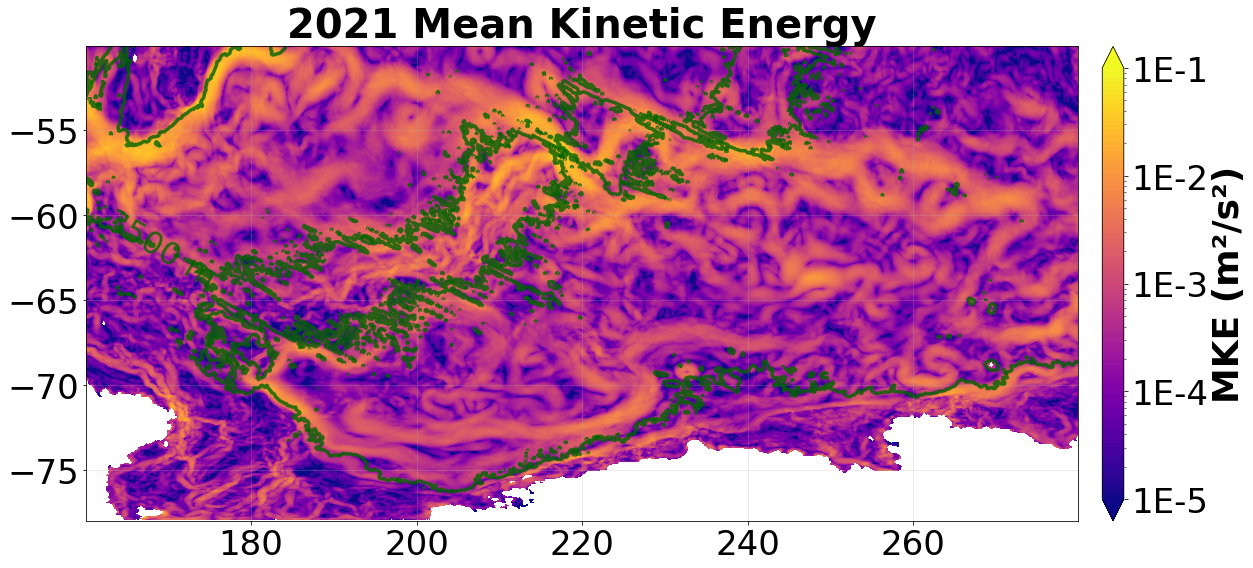

Plotting difference...


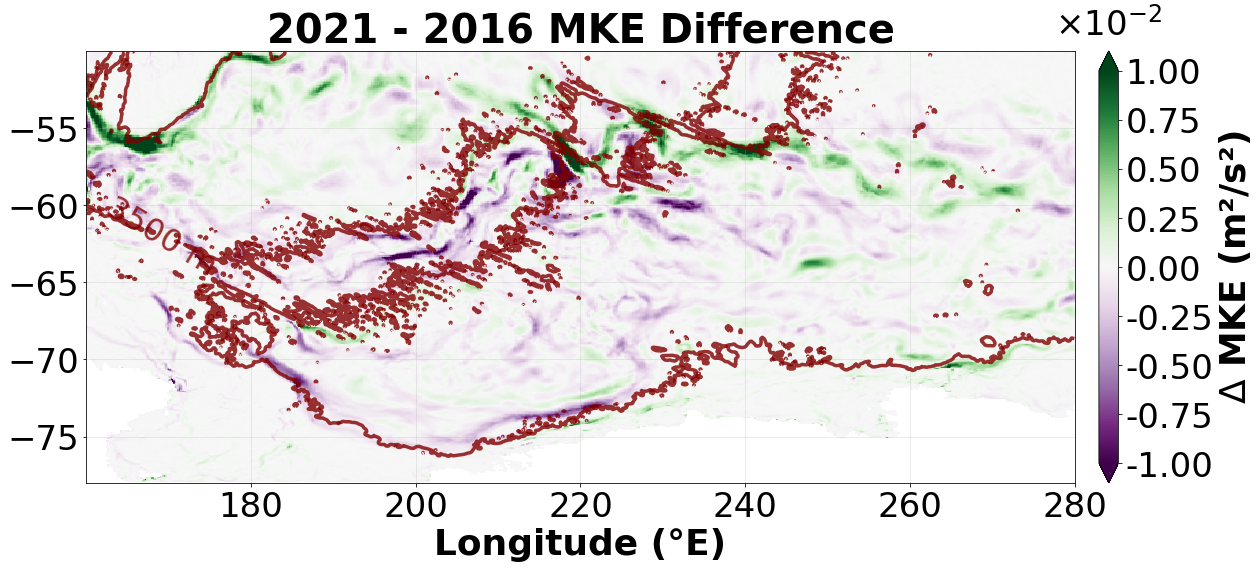


2021 - 2016 COMPARISON
Mean MKE 2016: 1.110299e-03 m²/s²
Mean MKE 2021: 1.026130e-03 m²/s²
Mean MKE difference: -8.416843e-05 m²/s²
Max increase: +3.978305e-02 m²/s²
Max decrease: -3.298519e-02 m²/s²
Percent change: -7.58%
Area with increase: 45.9%
Area with decrease: 54.1%

DONE!


In [20]:
# no baropsi

# nicer formatting

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import numpy as np
import xarray as xr
from xgcm import Grid
from scipy.interpolate import interp1d
from matplotlib.lines import Line2D

# ============================================================================
# PUBLICATION SETTINGS
# ============================================================================
BASE_FONTSIZE = 36 #20  # Adjust this one parameter to scale all fonts
TITLE_SIZE = BASE_FONTSIZE + 4
LABEL_SIZE = BASE_FONTSIZE
TICK_SIZE = BASE_FONTSIZE - 2
CBAR_LABEL_SIZE = BASE_FONTSIZE
CBAR_TICK_SIZE = BASE_FONTSIZE - 2
CONTOUR_LABEL_SIZE = BASE_FONTSIZE - 4
LEGEND_SIZE = BASE_FONTSIZE - 2
TEXT_SIZE = BASE_FONTSIZE - 2

# Just two years
year1 = 2016
year2 = 2021

# Get latitude/longitude ranges from the grid
lat_min = float(np.nanmin(uvel['YC'].values))
lat_max = -50.0
lon_min = 160.0
lon_max = 280.0

print(f"Region: Lon {lon_min}-{lon_max}°E, Lat {lat_min:.2f}-{lat_max}°S")
print(f"Using southern boundary: {lat_min:.2f}°S (for psi=0 reference)")

# Since UVEL and VVEL are on staggered grids, we need to use isel with index-based selection
# First, find the indices that correspond to our region

# For UVEL: uses YC and XG
uvel_yc = uvel['YC'].values
uvel_xg = uvel['XG'].values

# Find latitude indices (same for both U and V since we're using YC range)
lat_indices = np.where((uvel_yc >= lat_min) & (uvel_yc <= lat_max))[0]
lat_slice = slice(lat_indices.min(), lat_indices.max() + 1)

# Find longitude indices for UVEL (uses XG)
lon_indices_u = np.where((uvel_xg >= lon_min) & (uvel_xg <= lon_max))[0]
lon_slice_u = slice(lon_indices_u.min(), lon_indices_u.max() + 1)

# For VVEL: uses YG and XC
vvel_yg = vvel['YG'].values
vvel_xc = vvel['XC'].values

# Find indices for VVEL
lat_indices_v = np.where((vvel_yg >= lat_min) & (vvel_yg <= lat_max))[0]
lat_slice_v = slice(lat_indices_v.min(), lat_indices_v.max() + 1)

lon_indices_v = np.where((vvel_xc >= lon_min) & (vvel_xc <= lon_max))[0]
lon_slice_v = slice(lon_indices_v.min(), lon_indices_v.max() + 1)

print(f"\nUVEL indices: YC[{lat_slice.start}:{lat_slice.stop}], XG[{lon_slice_u.start}:{lon_slice_u.stop}]")
print(f"VVEL indices: YG[{lat_slice_v.start}:{lat_slice_v.stop}], XC[{lon_slice_v.start}:{lon_slice_v.stop}]")

# Load velocity data for the time period
print("\nLoading velocity data...")

# Select using isel for spatial dimensions and sel for time
uvel_subset = uvel['UVEL'].sel(time=slice(str(year1), str(year2))).isel(
    YC=lat_slice,
    XG=lon_slice_u
)

vvel_subset = vvel['VVEL'].sel(time=slice(str(year1), str(year2))).isel(
    YG=lat_slice_v,
    XC=lon_slice_v
)

print(f"U-vel subset shape: {uvel_subset.shape}")
print(f"V-vel subset shape: {vvel_subset.shape}")

# Get corresponding grid metrics from the already-loaded uvel/vvel coordinates
print("\nExtracting grid metrics from velocity datasets...")

hFacW_region = uvel_subset['hFacW']
hFacS_region = vvel_subset['hFacS']
drF_region = uvel_subset['drF']
dyG_region = uvel_subset['dyG']  ## unnecessary for final version

print(f"hFacW shape: {hFacW_region.shape}")
print(f"hFacS shape: {hFacS_region.shape}")
print(f"drF shape: {drF_region.shape}")
print(f"dyG shape: {dyG_region.shape}")  ## unnecessary for final version

# ============================================================================
# COMPUTE MKE (MEAN KINETIC ENERGY)
# ============================================================================
print("\n" + "="*70)
print("COMPUTING MEAN KINETIC ENERGY")
print("="*70)

# Create xgcm Grid object for proper interpolation
print("Setting up xgcm Grid for interpolation...")  ## unnecessary for final version

# We need to create a dataset with proper grid metrics
ds_u = uvel_subset.to_dataset(name='U')  ## unnecessary for final version
ds_v = vvel_subset.to_dataset(name='V')  ## unnecessary for final version

# Define grid coordinates for xgcm
coords = {
    'X': {'center': 'XC', 'left': 'XG'},
    'Y': {'center': 'YC', 'left': 'YG'},
    'Z': {'center': 'Z'}
}  ## unnecessary for final version

# Check what coordinates are available
print(f"U coords: {list(ds_u.coords)}")  ## unnecessary for final version
print(f"V coords: {list(ds_v.coords)}")  ## unnecessary for final version

# For year 2016
print(f"\nProcessing {year1}...")
u_2016 = uvel_subset.sel(time=str(year1))
v_2016 = vvel_subset.sel(time=str(year1))

# Time average first
u_time_mean_2016 = u_2016.mean(dim='time')
v_time_mean_2016 = v_2016.mean(dim='time')

# Calculate total depth for each point
depth_U_2016 = (drF_region * hFacW_region).sum(dim='Z')
depth_V_2016 = (drF_region * hFacS_region).sum(dim='Z')

# Thickness-weighted depth average
U_2016 = (u_time_mean_2016 * drF_region * hFacW_region).sum(dim='Z') / depth_U_2016.where(depth_U_2016 > 0)
V_2016 = (v_time_mean_2016 * drF_region * hFacS_region).sum(dim='Z') / depth_V_2016.where(depth_V_2016 > 0)

print(f"U_2016 shape: {U_2016.shape}, coords: {U_2016.dims}")
print(f"V_2016 shape: {V_2016.shape}, coords: {V_2016.dims}")

# Simple interpolation approach: average to cell centers
# U is on (YC, XG) grid - need to average in X to get to XC
# V is on (YG, XC) grid - need to average in Y to get to YC

# For U: interpolate from XG to XC (shift westward by averaging adjacent points)
# U_center will be on (YC, XC) but we lose one point in X
U_center_2016_vals = 0.5 * (U_2016.values[:, :-1] + U_2016.values[:, 1:])
# The XC coordinates that correspond to this
# Since U is on XG, when we average adjacent XG points, we get values approximately at XC
# We'll use the XC coordinates from vvel
xc_coords = vvel_subset.XC.values

# For V: interpolate from YG to YC (shift southward by averaging adjacent points)
V_center_2016_vals = 0.5 * (V_2016.values[:-1, :] + V_2016.values[1:, :])
yc_coords = uvel_subset.YC.values

print(f"U_center shape: {U_center_2016_vals.shape}")
print(f"V_center shape: {V_center_2016_vals.shape}")
print(f"XC coords length: {len(xc_coords)}")
print(f"YC coords length: {len(yc_coords)}")

# Now we need to get both on the same (YC, XC) grid
# U_center is on (full YC, reduced XC)
# V_center is on (reduced YC, full XC)

# Match dimensions by further interpolation
# Final grid will be (YC, XC) where both exist

# Check if U_center X dimension matches XC
if U_center_2016_vals.shape[1] == len(xc_coords):
    print("U_center X dimension matches XC perfectly")
    U_on_xc = U_center_2016_vals
else:
    print(f"U_center has {U_center_2016_vals.shape[1]} points, XC has {len(xc_coords)} points")
    # Interpolate U_center to XC
    from scipy.interpolate import interp1d
    xg_midpoints = 0.5 * (U_2016.XG.values[:-1] + U_2016.XG.values[1:])
    U_on_xc = np.zeros((len(yc_coords), len(xc_coords)))
    for i in range(len(yc_coords)):
        f = interp1d(xg_midpoints, U_center_2016_vals[i, :], 
                    bounds_error=False, fill_value=np.nan, kind='linear')
        U_on_xc[i, :] = f(xc_coords)

# Check if V_center Y dimension matches YC  
if V_center_2016_vals.shape[0] == len(yc_coords):
    print("V_center Y dimension matches YC perfectly")
    V_on_yc = V_center_2016_vals
else:
    print(f"V_center has {V_center_2016_vals.shape[0]} points, YC has {len(yc_coords)} points")
    # Interpolate V_center to YC
    yg_midpoints = 0.5 * (V_2016.YG.values[:-1] + V_2016.YG.values[1:])
    V_on_yc = np.zeros((len(yc_coords), len(xc_coords)))
    for j in range(len(xc_coords)):
        f = interp1d(yg_midpoints, V_center_2016_vals[:, j], 
                    bounds_error=False, fill_value=np.nan, kind='linear')
        V_on_yc[:, j] = f(yc_coords)

# Compute MKE
MKE_2016 = 0.5 * (U_on_xc**2 + V_on_yc**2)

print(f"MKE {year1} shape: {MKE_2016.shape}")
print(f"MKE {year1} range: {np.nanmin(MKE_2016):.6e} to {np.nanmax(MKE_2016):.6e} m²/s²")

## NOTE *_2020 VARIABLES USE YEAR 2021 IN FINAL PLOTS

# For year 2021
print(f"\nProcessing {year2}...")
u_2020 = uvel_subset.sel(time=str(year2))
v_2020 = vvel_subset.sel(time=str(year2))

# Time average first
u_time_mean_2020 = u_2020.mean(dim='time')
v_time_mean_2020 = v_2020.mean(dim='time')

# Calculate total depth for each point
depth_U_2020 = (drF_region * hFacW_region).sum(dim='Z')
depth_V_2020 = (drF_region * hFacS_region).sum(dim='Z')

# Thickness-weighted depth average
U_2020 = (u_time_mean_2020 * drF_region * hFacW_region).sum(dim='Z') / depth_U_2020.where(depth_U_2020 > 0)
V_2020 = (v_time_mean_2020 * drF_region * hFacS_region).sum(dim='Z') / depth_V_2020.where(depth_V_2020 > 0)

# Interpolate to cell centers
U_center_2020_vals = 0.5 * (U_2020.values[:, :-1] + U_2020.values[:, 1:])
V_center_2020_vals = 0.5 * (V_2020.values[:-1, :] + V_2020.values[1:, :])

# Match dimensions
if U_center_2020_vals.shape[1] == len(xc_coords):
    U_on_xc_2020 = U_center_2020_vals
else:
    U_on_xc_2020 = np.zeros((len(yc_coords), len(xc_coords)))
    for i in range(len(yc_coords)):
        f = interp1d(xg_midpoints, U_center_2020_vals[i, :], 
                    bounds_error=False, fill_value=np.nan, kind='linear')
        U_on_xc_2020[i, :] = f(xc_coords)

if V_center_2020_vals.shape[0] == len(yc_coords):
    V_on_yc_2020 = V_center_2020_vals
else:
    V_on_yc_2020 = np.zeros((len(yc_coords), len(xc_coords)))
    for j in range(len(xc_coords)):
        f = interp1d(yg_midpoints, V_center_2020_vals[:, j], 
                    bounds_error=False, fill_value=np.nan, kind='linear')
        V_on_yc_2020[:, j] = f(yc_coords)

# Compute MKE
MKE_2020 = 0.5 * (U_on_xc_2020**2 + V_on_yc_2020**2)

print(f"MKE {year2} range: {np.nanmin(MKE_2020):.6e} to {np.nanmax(MKE_2020):.6e} m²/s²")

# Compute difference
MKE_diff = MKE_2020 - MKE_2016

# Create DataArrays for easy plotting
MKE_2016_da = xr.DataArray(
    MKE_2016,
    coords={'YC': yc_coords, 'XC': xc_coords},
    dims=['YC', 'XC']
)

MKE_2020_da = xr.DataArray(
    MKE_2020,
    coords={'YC': yc_coords, 'XC': xc_coords},
    dims=['YC', 'XC']
)

MKE_diff_da = xr.DataArray(
    MKE_diff,
    coords={'YC': yc_coords, 'XC': xc_coords},
    dims=['YC', 'XC']
)

# ============================================================================
# GET BATHYMETRY
# ============================================================================
print("\nLoading bathymetry...")
lon_grid = grid['XC'].values
lat_grid = grid['YC'].values
bathy_grid = grid['Depth'].values

mask_lon = (lon_grid >= lon_min) & (lon_grid <= lon_max)
mask_lat = (lat_grid >= lat_min) & (lat_grid <= lat_max)
mask = mask_lon & mask_lat
ny_indices_b, nx_indices_b = np.where(mask)
ny_min_b, ny_max_b = ny_indices_b.min(), ny_indices_b.max()
nx_min_b, nx_max_b = nx_indices_b.min(), nx_indices_b.max()

lon_bathy = lon_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]
lat_bathy = lat_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]
bathy_subset = bathy_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]

# ============================================================================
# PLOTTING
# ============================================================================
print("\n" + "="*70)
print("CREATING PLOTS")
print("="*70)

# Set up logarithmic colormap for MKE
vmin = 1e-5
vmax = 1e-1
norm = mcolors.LogNorm(vmin=vmin, vmax=vmax)
levels = np.logspace(np.log10(vmin), np.log10(vmax), 100)  # For contourf

# For the difference plot, we need linear scale
diff_max = 1e-2
diff_norm = mcolors.TwoSlopeNorm(vmin=-diff_max, vcenter=0, vmax=diff_max)

print(f"MKE range for colorbar: {vmin:.1e} to {vmax:.1e} m²/s²")
print(f"Difference range: {np.nanmin(MKE_diff):.3e} to {np.nanmax(MKE_diff):.3e} m²/s²")

# Figure 1: 2016
print(f"\nPlotting {year1}...")
fig1, ax1 = plt.subplots(figsize=(18, 8))

# MKE with logarithmic colormap
levels = np.logspace(np.log10(vmin), np.log10(vmax), 100)
cf1 = ax1.contourf(MKE_2016_da.XC, MKE_2016_da.YC, MKE_2016_da.values,
                   levels=levels, norm=norm, cmap='plasma', extend='both')

# Bathymetry
cs_bathy1 = ax1.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='darkgreen', linewidths=3.5, alpha=0.8)
ax1.clabel(cs_bathy1, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax1.set_title(f'{year1} Mean Kinetic Energy', 
              fontsize=TITLE_SIZE, fontweight='bold')
# ax1.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax1.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.tick_params(labelsize=TICK_SIZE)

# Colorbar with logarithmic ticks and arrows
cbar1 = plt.colorbar(cf1, ax=ax1, pad=0.02, extend='both')
cbar1.set_label('MKE (m²/s²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
ticks = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
cbar1.set_ticks(ticks)
cbar1.set_ticklabels(['1E-5', '1E-4', '1E-3', '1E-2', '1E-1'])
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig1.savefig(f'v1_MKE_{year1}_no_baropsi.png', dpi=300, bbox_inches='tight', facecolor='white')
fig1.savefig(f'v1_MKE_{year1}_no_baropsi.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 2: 2021
print(f"Plotting {year2}...")
fig2, ax2 = plt.subplots(figsize=(18, 8))

# MKE with logarithmic colormap
cf2 = ax2.contourf(MKE_2020_da.XC, MKE_2020_da.YC, MKE_2020_da.values,
                   levels=levels, norm=norm, cmap='plasma', extend='both')

# Bathymetry
cs_bathy2 = ax2.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='darkgreen', linewidths=3.5, alpha=0.8)
ax2.clabel(cs_bathy2, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax2.set_title(f'{year2} Mean Kinetic Energy', 
              fontsize=TITLE_SIZE, fontweight='bold')
# ax2.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax2.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.tick_params(labelsize=TICK_SIZE)

# Colorbar with logarithmic ticks and arrows
cbar2 = plt.colorbar(cf2, ax=ax2, pad=0.02, extend='both')
cbar2.set_label('MKE (m²/s²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
cbar2.set_ticks(ticks)
cbar2.set_ticklabels(['1E-5', '1E-4', '1E-3', '1E-2', '1E-1'])
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig2.savefig(f'v1_MKE_{year2}_no_baropsi.png', dpi=300, bbox_inches='tight', facecolor='white')
fig2.savefig(f'v1_MKE_{year2}_no_baropsi.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 3: Difference
print("Plotting difference...")
fig3, ax3 = plt.subplots(figsize=(18, 8))

# # MKE difference with diverging colormap centered at 0
# diff_norm = mcolors.TwoSlopeNorm(vmin=-diff_max, vcenter=0, vmax=diff_max)
# cf3 = ax3.pcolormesh(MKE_diff_da.XC, MKE_diff_da.YC, MKE_diff_da.values,
#                      cmap='PuOr_r', norm=diff_norm, shading='auto')

# Set up the range in units of 10^-2
diff_max_scaled = 1.0  # Range will be ±1.0 in display units
diff_max_actual = diff_max_scaled * 1e-2  # Actual range ±0.01 m²/s²

# MKE difference with diverging colormap centered at 0
diff_norm = mcolors.TwoSlopeNorm(vmin=-diff_max_actual, vcenter=0, vmax=diff_max_actual)
cf3 = ax3.pcolormesh(MKE_diff_da.XC, MKE_diff_da.YC, MKE_diff_da.values,
                     cmap='PRGn', norm=diff_norm, shading='auto')

# Bathymetry
cs_bathy3 = ax3.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='maroon', linewidths=3.5, alpha=0.8)
ax3.clabel(cs_bathy3, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax3.set_title(f'{year2} - {year1} MKE Difference', 
              fontsize=TITLE_SIZE, fontweight='bold')
ax3.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
# ax3.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.tick_params(labelsize=TICK_SIZE)

# # Colorbar with scientific notation
# cbar3 = plt.colorbar(cf3, ax=ax3, pad=0.02)
# cbar3.set_label('$\Delta$ MKE (m²/s²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
# cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Colorbar with scientific notation and arrows
cbar3 = plt.colorbar(cf3, ax=ax3, pad=0.02, extend='both')
cbar3.set_label('$\Delta$ MKE (m²/s²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')

# Set ticks in scaled units
tick_values = np.array([-1.0, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1.0]) * 1e-2
cbar3.set_ticks(tick_values)
cbar3.set_ticklabels(['-1.00', '-0.75', '-0.50', '-0.25', '0.00', 
                       '0.25', '0.50', '0.75', '1.00'])

# Add the ×10^-2 label above colorbar
cbar3.ax.text(0.5, 1.02, r'$\times 10^{-2}$', transform=cbar3.ax.transAxes,
              ha='center', va='bottom', fontsize=CBAR_TICK_SIZE)

cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Add mean difference text
mean_diff = np.nanmean(MKE_diff)
# ax3.text(0.02, 0.98, f'Mean Difference: {mean_diff:.3e} m²/s²',
#         transform=ax3.transAxes, fontsize=TEXT_SIZE, fontweight='bold',
#         verticalalignment='top',
#         bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', 
#                  linewidth=2, alpha=0.95))

plt.tight_layout()
fig3.savefig(f'v1_MKE_difference_{year2}-{year1}_no_baropsi.png', dpi=300, bbox_inches='tight', facecolor='white')
fig3.savefig(f'v1_MKE_difference_{year2}-{year1}_no_baropsi.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# ============================================================================
# STATISTICS
# ============================================================================
print("\n" + "="*70)
print(f"{year2} - {year1} COMPARISON")
print("="*70)
print(f"Mean MKE {year1}: {np.nanmean(MKE_2016):.6e} m²/s²")
print(f"Mean MKE {year2}: {np.nanmean(MKE_2020):.6e} m²/s²")
print(f"Mean MKE difference: {mean_diff:+.6e} m²/s²")
print(f"Max increase: {np.nanmax(MKE_diff):+.6e} m²/s²")
print(f"Max decrease: {np.nanmin(MKE_diff):+.6e} m²/s²")
print(f"Percent change: {(mean_diff / np.nanmean(MKE_2016)) * 100:+.2f}%")
print(f"Area with increase: {np.sum(MKE_diff > 0) / np.sum(~np.isnan(MKE_diff)) * 100:.1f}%")
print(f"Area with decrease: {np.sum(MKE_diff < 0) / np.sum(~np.isnan(MKE_diff)) * 100:.1f}%")

print("\n" + "="*70)
print("DONE!")
print("="*70)


PROCESSING ZONAL WIND STRESS
Region: Lon 160.0-280.0°E, Lat -90.0--50.0°S

Loading zonal wind stress data...
Wind stress subset shape: (72, 427, 721)
Coordinates: XG=(721,), YC=(427,)

Processing 2016...
Processing 2021...

Wind stress 2016 range: -1.334398e-01 to 1.947967e-01 N/m²
Wind stress 2021 range: -2.228307e-01 to 2.371497e-01 N/m²
Wind stress difference range: -9.747797e-02 to 1.027609e-01 N/m²

Loading bathymetry...

CREATING PLOTS
Wind stress colorbar range: ±0.30 N/m²
Difference colorbar range: ±0.110 N/m²

Plotting 2016...


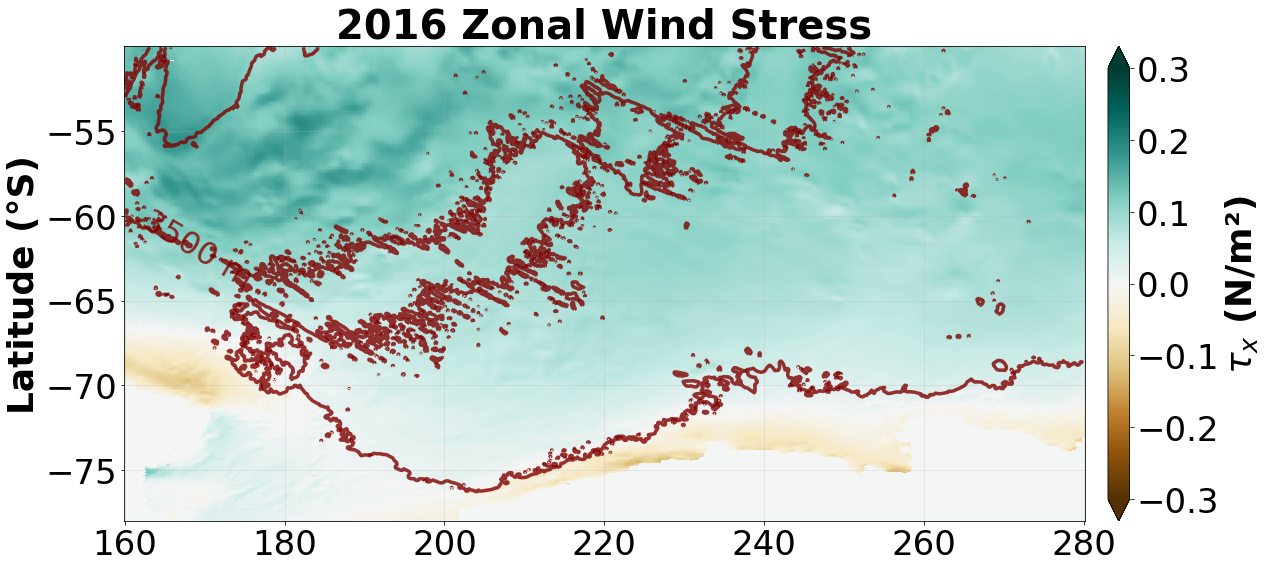

Plotting 2021...


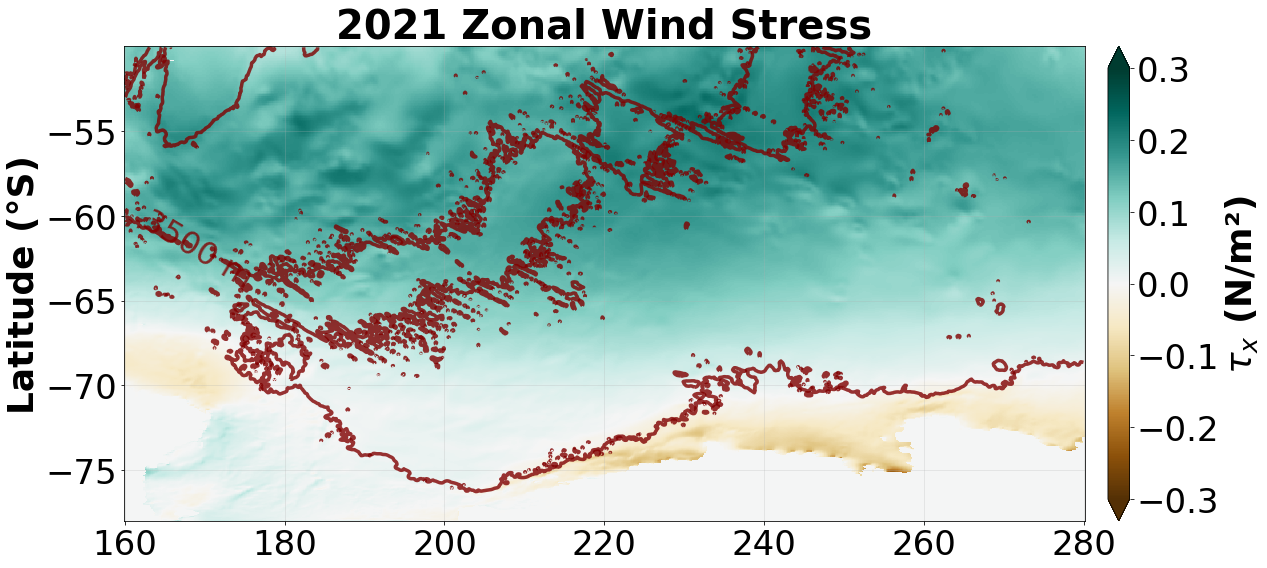

Plotting difference...


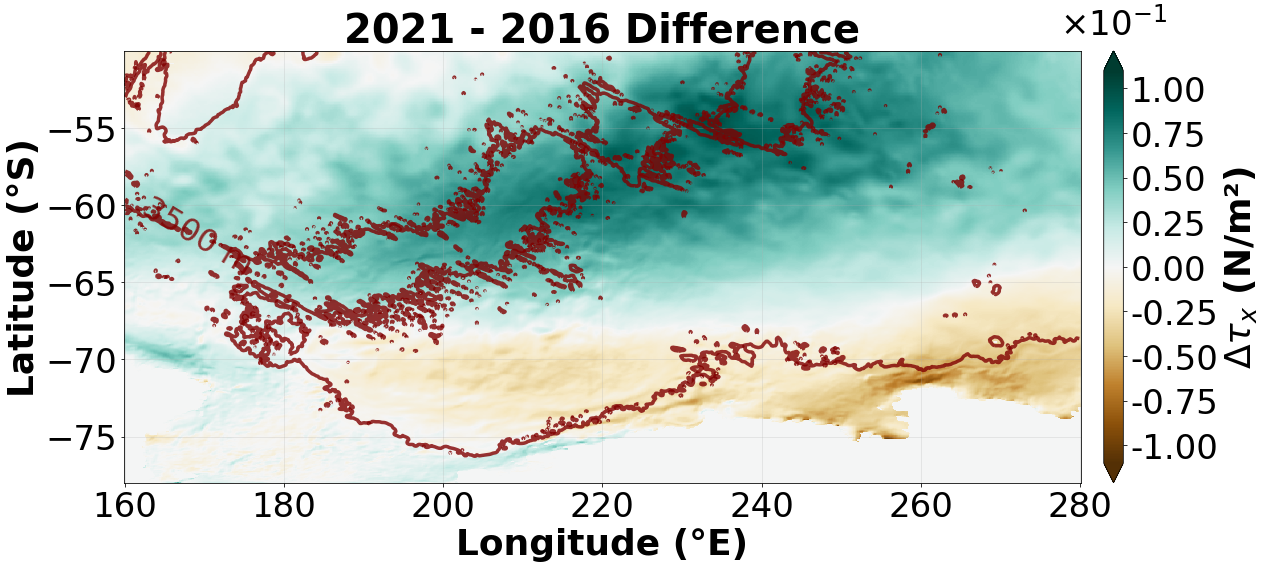


2021 - 2016 WIND STRESS COMPARISON
Mean τx 2016: 5.330212e-02 N/m²
Mean τx 2021: 6.817701e-02 N/m²
Mean τx difference: +1.487490e-02 N/m²
Max increase: +1.027609e-01 N/m²
Max decrease: -9.747797e-02 N/m²
Percent change: +27.91%
Area with increase: 55.9%
Area with decrease: 28.8%

DONE!


In [19]:
# Zonal Wind Stress Plots with Publication Styling

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# ============================================================================
# PUBLICATION SETTINGS
# ============================================================================
BASE_FONTSIZE = 36 #20  # Adjust this one parameter to scale all fonts
TITLE_SIZE = BASE_FONTSIZE + 4
LABEL_SIZE = BASE_FONTSIZE
TICK_SIZE = BASE_FONTSIZE - 2
CBAR_LABEL_SIZE = BASE_FONTSIZE
CBAR_TICK_SIZE = BASE_FONTSIZE - 2
CONTOUR_LABEL_SIZE = BASE_FONTSIZE - 4
LEGEND_SIZE = BASE_FONTSIZE - 2
TEXT_SIZE = BASE_FONTSIZE - 2

# Just two years
year1 = 2016
year2 = 2021

# ============================================================================
# LOAD AND PROCESS ZONAL WIND STRESS DATA
# ============================================================================
print("\n" + "="*70)
print("PROCESSING ZONAL WIND STRESS")
print("="*70)

# Define region
lat_min = -90.0  # or -75.0 if you prefer
lat_max = -50.0
lon_min = 160.0
lon_max = 280.0

print(f"Region: Lon {lon_min}-{lon_max}°E, Lat {lat_min}-{lat_max}°S")

# Load zonal wind stress for the region
print("\nLoading zonal wind stress data...")
taux_subset = taux['oceTAUX'].sel(
    XG=slice(lon_min, lon_max),
    YC=slice(lat_min, lat_max),
    time=slice(str(year1), str(year2))
)

print(f"Wind stress subset shape: {taux_subset.shape}")
print(f"Coordinates: XG={taux_subset.XG.shape}, YC={taux_subset.YC.shape}")

# Extract data for each year
print(f"\nProcessing {year1}...")
taux_2016 = taux_subset.sel(time=str(year1))
taux_2016_mean = taux_2016.mean(dim='time')

print(f"Processing {year2}...")
taux_2020 = taux_subset.sel(time=str(year2))
taux_2020_mean = taux_2020.mean(dim='time')

# Compute difference
taux_diff = taux_2020_mean - taux_2016_mean

print(f"\nWind stress {year1} range: {taux_2016_mean.min().values:.6e} to {taux_2016_mean.max().values:.6e} N/m²")
print(f"Wind stress {year2} range: {taux_2020_mean.min().values:.6e} to {taux_2020_mean.max().values:.6e} N/m²")
print(f"Wind stress difference range: {taux_diff.min().values:.6e} to {taux_diff.max().values:.6e} N/m²")

# ============================================================================
# GET BATHYMETRY
# ============================================================================
print("\nLoading bathymetry...")
lon_grid = grid['XC'].values
lat_grid = grid['YC'].values
bathy_grid = grid['Depth'].values

mask_lon = (lon_grid >= lon_min) & (lon_grid <= lon_max)
mask_lat = (lat_grid >= lat_min) & (lat_grid <= lat_max)
mask = mask_lon & mask_lat
ny_indices_b, nx_indices_b = np.where(mask)
ny_min_b, ny_max_b = ny_indices_b.min(), ny_indices_b.max()
nx_min_b, nx_max_b = nx_indices_b.min(), nx_indices_b.max()

lon_bathy = lon_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]
lat_bathy = lat_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]
bathy_subset = bathy_grid[ny_min_b:ny_max_b+1, nx_min_b:nx_max_b+1]

# ============================================================================
# PLOTTING
# ============================================================================
print("\n" + "="*70)
print("CREATING PLOTS")
print("="*70)

# Determine colormap ranges based on data
# For wind stress, we'll use a symmetric diverging colormap
tau_max = max(abs(taux_2016_mean.min().values), abs(taux_2016_mean.max().values),
              abs(taux_2020_mean.min().values), abs(taux_2020_mean.max().values))
tau_max = np.ceil(tau_max * 10) / 10  # Round up to nearest 0.1

print(f"Wind stress colorbar range: ±{tau_max:.2f} N/m²")

# For difference plot
diff_max = max(abs(taux_diff.min().values), abs(taux_diff.max().values))
diff_max = np.ceil(diff_max * 100) / 100  # Round up to nearest 0.01

print(f"Difference colorbar range: ±{diff_max:.3f} N/m²")

# Set up colormaps
tau_norm = mcolors.TwoSlopeNorm(vmin=-tau_max, vcenter=0, vmax=tau_max)
diff_norm = mcolors.TwoSlopeNorm(vmin=-diff_max, vcenter=0, vmax=diff_max)

# Figure 1: 2016
print(f"\nPlotting {year1}...")
fig1, ax1 = plt.subplots(figsize=(18, 8))

# Wind stress with diverging colormap
cf1 = ax1.pcolormesh(taux_2016_mean.XG, taux_2016_mean.YC, taux_2016_mean.values,
                     cmap='BrBG', norm=tau_norm, shading='auto')

# Bathymetry
cs_bathy1 = ax1.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='maroon', linewidths=3.5, alpha=0.8)
ax1.clabel(cs_bathy1, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax1.set_title(f'{year1} Zonal Wind Stress', 
              fontsize=TITLE_SIZE, fontweight='bold')
# ax1.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
ax1.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax1.grid(True, alpha=0.3)
ax1.tick_params(labelsize=TICK_SIZE)

# Colorbar
cbar1 = plt.colorbar(cf1, ax=ax1, pad=0.02, extend='both')
cbar1.set_label(r'$\tau_x$ (N/m²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
cbar1.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig1.savefig(f'v1_taux_{year1}.png', dpi=300, bbox_inches='tight', facecolor='white')
fig1.savefig(f'v1_taux_{year1}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 2: 2021
print(f"Plotting {year2}...")
fig2, ax2 = plt.subplots(figsize=(18, 8))

# Wind stress with diverging colormap
cf2 = ax2.pcolormesh(taux_2020_mean.XG, taux_2020_mean.YC, taux_2020_mean.values,
                     cmap='BrBG', norm=tau_norm, shading='auto')

# Bathymetry
cs_bathy2 = ax2.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='maroon', linewidths=3.5, alpha=0.8)
ax2.clabel(cs_bathy2, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

ax2.set_title(f'{year2} Zonal Wind Stress', 
              fontsize=TITLE_SIZE, fontweight='bold')
# ax2.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
ax2.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.tick_params(labelsize=TICK_SIZE)

# Colorbar
cbar2 = plt.colorbar(cf2, ax=ax2, pad=0.02, extend='both')
cbar2.set_label(r'$\tau_x$ (N/m²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
cbar2.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig2.savefig(f'v1_taux_{year2}.png', dpi=300, bbox_inches='tight', facecolor='white')
fig2.savefig(f'v1_taux_{year2}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# Figure 3: Difference
print("Plotting difference...")
fig3, ax3 = plt.subplots(figsize=(18, 8))

# Define scaled tick values for 10^-1 magnitude
scale_factor = 1e-1
tick_values = np.array([-1.0, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1.0]) * scale_factor
tick_labels = ['-1.00', '-0.75', '-0.50', '-0.25', '0.00', 
               '0.25', '0.50', '0.75', '1.00']

# Wind stress difference with diverging colormap
cf3 = ax3.pcolormesh(taux_diff.XG, taux_diff.YC, taux_diff.values,
                     cmap='BrBG', norm=diff_norm, shading='auto')

# Bathymetry
cs_bathy3 = ax3.contour(lon_bathy, lat_bathy, bathy_subset,
                        levels=[3500], colors='maroon', linewidths=3.5, alpha=0.8)
ax3.clabel(cs_bathy3, inline=True, fontsize=CONTOUR_LABEL_SIZE, fmt='%0.0f m')

# ax3.set_title(f'{year2} - {year1} Zonal Wind Stress Difference', 
#               fontsize=TITLE_SIZE, fontweight='bold')
ax3.set_title(f'{year2} - {year1} Difference', 
              fontsize=TITLE_SIZE, fontweight='bold')
ax3.set_xlabel('Longitude (°E)', fontsize=LABEL_SIZE, fontweight='bold')
ax3.set_ylabel('Latitude (°S)', fontsize=LABEL_SIZE, fontweight='bold')
ax3.grid(True, alpha=0.3)
ax3.tick_params(labelsize=TICK_SIZE)

# # Colorbar
# cbar3 = plt.colorbar(cf3, ax=ax3, pad=0.02, extend='both')
# cbar3.set_label(r'$\Delta\tau_x$ (N/m²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')
# cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)

# Colorbar with scaled scientific notation
cbar3 = plt.colorbar(cf3, ax=ax3, pad=0.02, extend='both')
cbar3.set_label(r'$\Delta\tau_x$ (N/m²)', fontsize=CBAR_LABEL_SIZE, fontweight='bold')

# Apply custom ticks and labels
cbar3.set_ticks(tick_values)
cbar3.set_ticklabels(tick_labels)

# Add the ×10^-1 exponent label above the colorbar
cbar3.ax.text(0.5, 1.02, r'$\times 10^{-1}$', transform=cbar3.ax.transAxes,
              ha='center', va='bottom', fontsize=CBAR_TICK_SIZE)

cbar3.ax.tick_params(labelsize=CBAR_TICK_SIZE)

plt.tight_layout()
fig3.savefig(f'v1_taux_difference_{year2}-{year1}.png', dpi=300, bbox_inches='tight', facecolor='white')
fig3.savefig(f'v1_taux_difference_{year2}-{year1}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

# ============================================================================
# STATISTICS
# ============================================================================
print("\n" + "="*70)
print(f"{year2} - {year1} WIND STRESS COMPARISON")
print("="*70)
print(f"Mean τx {year1}: {taux_2016_mean.mean().values:.6e} N/m²")
print(f"Mean τx {year2}: {taux_2020_mean.mean().values:.6e} N/m²")
mean_diff = taux_diff.mean().values
print(f"Mean τx difference: {mean_diff:+.6e} N/m²")
print(f"Max increase: {taux_diff.max().values:+.6e} N/m²")
print(f"Max decrease: {taux_diff.min().values:+.6e} N/m²")
print(f"Percent change: {(mean_diff / taux_2016_mean.mean().values) * 100:+.2f}%")
print(f"Area with increase: {np.sum(taux_diff.values > 0) / np.sum(~np.isnan(taux_diff.values)) * 100:.1f}%")
print(f"Area with decrease: {np.sum(taux_diff.values < 0) / np.sum(~np.isnan(taux_diff.values)) * 100:.1f}%")

print("\n" + "="*70)
print("DONE!")
print("="*70)